## Problema 4 — Classificação de Risco de Crédito com Árvore de Decisão

### 1. Carregamento e Exploração dos Dados

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

dataset = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

df = dataset.frame.copy()

display(df.head())

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


### 1.1. Análise exploratória

In [2]:
print("Dimensões:", df.shape)

print("\nInformações gerais:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nEstatísticas descritivas:")
display(df.describe(include="all"))

print("\nRegistros duplicados:", df.duplicated().sum())

Dimensões: (1000, 21)

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   categor

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
count,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,1000,...,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000
unique,4,NaN,5,10,NaN,5,5,NaN,4,3,...,4,NaN,3,3,NaN,4,NaN,2,2,2
top,no checking,NaN,existing paid,radio/tv,NaN,<100,1<=X<4,NaN,male single,none,...,car,NaN,none,own,NaN,skilled,NaN,none,yes,good
freq,394,NaN,530,280,NaN,603,339,NaN,548,907,...,332,NaN,814,713,NaN,630,NaN,596,963,700
mean,NaN,20.903000,NaN,NaN,3271.258000,NaN,NaN,2.973000,NaN,NaN,...,NaN,35.546000,NaN,NaN,1.407000,NaN,1.155000,NaN,NaN,NaN
std,NaN,12.058814,NaN,NaN,2822.736876,NaN,NaN,1.118715,NaN,NaN,...,NaN,11.375469,NaN,NaN,0.577654,NaN,0.362086,NaN,NaN,NaN
min,NaN,4.000000,NaN,NaN,250.000000,NaN,NaN,1.000000,NaN,NaN,...,NaN,19.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN
25%,NaN,12.000000,NaN,NaN,1365.500000,NaN,NaN,2.000000,NaN,NaN,...,NaN,27.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN
50%,NaN,18.000000,NaN,NaN,2319.500000,NaN,NaN,3.000000,NaN,NaN,...,NaN,33.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN
75%,NaN,24.000000,NaN,NaN,3972.250000,NaN,NaN,4.000000,NaN,NaN,...,NaN,42.000000,NaN,NaN,2.000000,NaN,1.000000,NaN,NaN,NaN



Registros duplicados: 0


In [3]:
X = df.drop(columns=["class"])
y = df["class"]

variaveis_numericas = X.select_dtypes(
    include="number"
).columns.tolist()

variaveis_categoricas = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Variáveis numéricas:")
print(variaveis_numericas)

print("\nVariáveis categóricas:")
print(variaveis_categoricas)

print("\nQuantidade de variáveis numéricas:",
      len(variaveis_numericas))

print("Quantidade de variáveis categóricas:",
      len(variaveis_categoricas))

Variáveis numéricas:
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Variáveis categóricas:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Quantidade de variáveis numéricas: 7
Quantidade de variáveis categóricas: 13


## 2. Preparação dos Dados

### 2.1. Codificação da variável alvo

In [4]:
print("Classes originais:")
print(y.value_counts())

# Converte os rótulos
y = y.astype(str).map({
    "good": 0,
    "bad": 1
}).astype(int)

# Verifica a distribuição binária
print("\nClasses após codificação:")
print(y.value_counts().sort_index())

# Calcula os percentuais
distribuicao = pd.DataFrame({
    "Quantidade": y.value_counts().sort_index(),
    "Percentual (%)": (
        y.value_counts(normalize=True).sort_index() * 100
    )
})

distribuicao.index = ["Bom Risco", "Mau Risco"]

display(distribuicao.round(2))

Classes originais:
class
good    700
bad     300
Name: count, dtype: int64

Classes após codificação:
class
0    700
1    300
Name: count, dtype: int64


,Quantidade,Percentual (%)
Bom Risco,700,70.0
Mau Risco,300,30.0


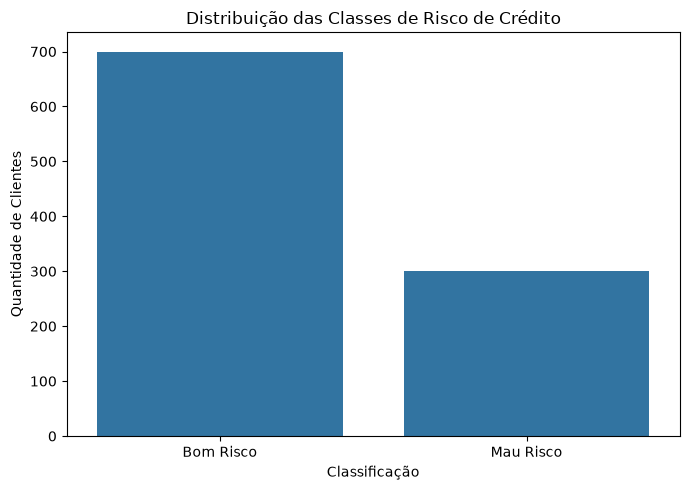

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    order=[0, 1]
)

plt.xticks(
    ticks=[0, 1],
    labels=["Bom Risco", "Mau Risco"]
)

plt.xlabel("Classificação")
plt.ylabel("Quantidade de Clientes")
plt.title("Distribuição das Classes de Risco de Crédito")

plt.tight_layout()
plt.show()

### 2.2. Divisão dos dados em treino e teste

In [6]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Amostras de treino:", X_treino.shape)
print("Amostras de teste:", X_teste.shape)

print("\nDistribuição no treino:")
print(y_treino.value_counts().sort_index())

print("\nDistribuição no teste:")
print(y_teste.value_counts().sort_index())

Amostras de treino: (800, 20)
Amostras de teste: (200, 20)

Distribuição no treino:
class
0    560
1    240
Name: count, dtype: int64

Distribuição no teste:
class
0    140
1     60
Name: count, dtype: int64


### 2.3. Codificação das variáveis categóricas

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Cria o codificador categórico
codificador = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Cria o pré-processador
preprocessador = ColumnTransformer(
    transformers=[
        ("categoricas", codificador, variaveis_categoricas),
        ("numericas", "passthrough", variaveis_numericas)
    ]
)

X_treino_proc = preprocessador.fit_transform(X_treino)

X_teste_proc = preprocessador.transform(X_teste)

print("Formato do treino:", X_treino_proc.shape)
print("Formato do teste:", X_teste_proc.shape)

Formato do treino: (800, 61)
Formato do teste: (200, 61)


### 2.4. Verificação dos dados processados

In [8]:
nomes_atributos = preprocessador.get_feature_names_out()

print("Atributos originais:", X.shape[1])
print("Atributos após codificação:", len(nomes_atributos))

print("\nTreinamento:", X_treino_proc.shape)
print("Teste:", X_teste_proc.shape)

print("\nValores ausentes no treino:",
      pd.isnull(X_treino_proc).sum())

print("Valores ausentes no teste:",
      pd.isnull(X_teste_proc).sum())

print("\nAtributos transformados:")
print(nomes_atributos)

Atributos originais: 20
Atributos após codificação: 61

Treinamento: (800, 61)
Teste: (200, 61)

Valores ausentes no treino: 0
Valores ausentes no teste: 0

Atributos transformados:
['categoricas__checking_status_0<=X<200' 'categoricas__checking_status_<0'
 'categoricas__checking_status_>=200'
 'categoricas__checking_status_no checking'
 'categoricas__credit_history_all paid'
 'categoricas__credit_history_critical/other existing credit'
 'categoricas__credit_history_delayed previously'
 'categoricas__credit_history_existing paid'
 'categoricas__credit_history_no credits/all paid'
 'categoricas__purpose_business' 'categoricas__purpose_domestic appliance'
 'categoricas__purpose_education'
 'categoricas__purpose_furniture/equipment' 'categoricas__purpose_new car'
 'categoricas__purpose_other' 'categoricas__purpose_radio/tv'
 'categoricas__purpose_repairs' 'categoricas__purpose_retraining'
 'categoricas__purpose_used car' 'categoricas__savings_status_100<=X<500'
 'categoricas__savings_stat

### 2.5. Conversão dos dados para tensores PyTorch

In [9]:
X_treino_tensor = torch.tensor(
    X_treino_proc,
    dtype=torch.float32
)

X_teste_tensor = torch.tensor(
    X_teste_proc,
    dtype=torch.float32
)

y_treino_tensor = torch.tensor(
    y_treino.to_numpy(),
    dtype=torch.long
)

y_teste_tensor = torch.tensor(
    y_teste.to_numpy(),
    dtype=torch.long
)

print("X treino:", X_treino_tensor.shape)
print("X teste:", X_teste_tensor.shape)

print("y treino:", y_treino_tensor.shape)
print("y teste:", y_teste_tensor.shape)

X treino: torch.Size([800, 61])
X teste: torch.Size([200, 61])
y treino: torch.Size([800])
y teste: torch.Size([200])
